# RetailLens — Exploratory Data Analysis

## Project Overview
RetailLens is a retail sales analysis project focused on understanding
sales performance, customer purchasing behaviour, product demand,
and geographical revenue distribution.

## Objectives
- Analyse monthly revenue trends.
- Understand customer purchasing behaviour.
- Identify top-performing products.
- Analyse country-wise sales performance.
- Extract meaningful business insights.

In [122]:
import pandas as pd
import matplotlib.pyplot as plt

# Load the cleaned dataset
df = pd.read_csv("../data/processed/online_retail_cleaned.csv")

# Display the first five records
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [123]:
# Dataset dimensions
print("Dataset Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns.tolist())

# Data types
print("\nData Types:")
print(df.dtypes)

# First five records
df.head()

Dataset Shape: (536641, 9)

Columns:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue']

Data Types:
InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
Revenue        float64
dtype: object


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


## 2. Date Preparation

The InvoiceDate column is converted into a datetime format to enable
time-based analysis.

A YearMonth column is also created to group transactions by month.

In [124]:
# Convert InvoiceDate to datetime
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Extract year and month
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

# Verify the conversion
print("Data Type:", df["InvoiceDate"].dtype)

print("\nDate Range:")
print("First transaction:", df["InvoiceDate"].min())
print("Last transaction:", df["InvoiceDate"].max())

# Preview the new columns
df[["InvoiceDate", "YearMonth"]].head(10)

Data Type: datetime64[us]

Date Range:
First transaction: 2010-12-01 08:26:00
Last transaction: 2011-12-09 12:50:00


,InvoiceDate,YearMonth
0,2010-12-01 08:26:00,2010-12
1,2010-12-01 08:26:00,2010-12
2,2010-12-01 08:26:00,2010-12
3,2010-12-01 08:26:00,2010-12
4,2010-12-01 08:26:00,2010-12
5,2010-12-01 08:26:00,2010-12
6,2010-12-01 08:26:00,2010-12
7,2010-12-01 08:28:00,2010-12
8,2010-12-01 08:28:00,2010-12
9,2010-12-01 08:34:00,2010-12


## 3. Monthly Revenue Analysis

This section analyses how revenue changes over time.

Revenue is grouped by month to identify trends, stronger sales periods,
and weaker sales periods.

In [125]:
monthly_revenue = df.groupby("YearMonth")["Revenue"].sum()

monthly_revenue

YearMonth
2010-12     746723.610
2011-01     558448.560
2011-02     497026.410
2011-03     682013.980
2011-04     492367.841
2011-05     722094.100
2011-06     689977.230
2011-07     680156.991
2011-08     681386.460
2011-09    1017596.682
2011-10    1069368.230
2011-11    1456145.800
2011-12     432701.060
Freq: M, Name: Revenue, dtype: float64

In [126]:
complete_months = monthly_revenue[monthly_revenue.index != "2011-12"]

complete_months

YearMonth
2010-12     746723.610
2011-01     558448.560
2011-02     497026.410
2011-03     682013.980
2011-04     492367.841
2011-05     722094.100
2011-06     689977.230
2011-07     680156.991
2011-08     681386.460
2011-09    1017596.682
2011-10    1069368.230
2011-11    1456145.800
Freq: M, Name: Revenue, dtype: float64

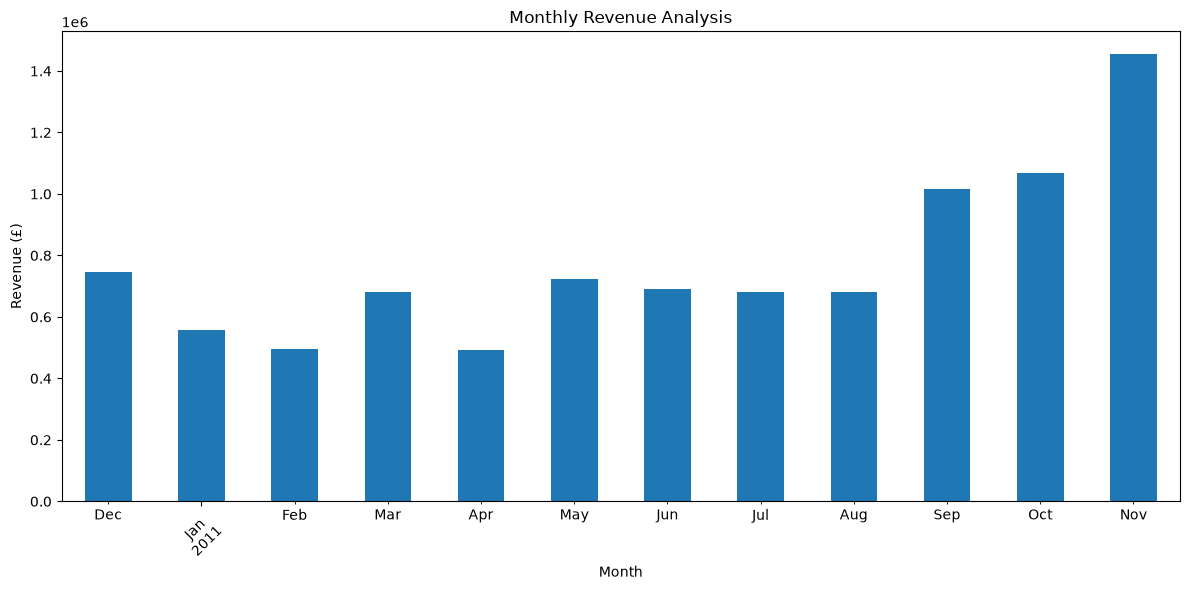

In [127]:
plt.figure(figsize=(12, 6))

complete_months.astype(float).plot(kind="bar")

plt.title("Monthly Revenue Analysis")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

## 4. Customer Purchasing Behaviour

This section examines customer activity over time.

We will analyse the number of purchasing customers and later compare
customer activity with revenue and order patterns.

In [128]:
# Keep transactions that generated positive revenue
sales_df = df[df["Revenue"] > 0].copy()

# Count unique purchasing customers each month
monthly_customers = sales_df.groupby("YearMonth")["CustomerID"].nunique()

monthly_customers

YearMonth
2010-12     885
2011-01     741
2011-02     758
2011-03     974
2011-04     856
2011-05    1056
2011-06     991
2011-07     949
2011-08     935
2011-09    1266
2011-10    1364
2011-11    1664
2011-12     615
Freq: M, Name: CustomerID, dtype: int64

In [129]:
# Keep only positive-revenue transactions with an identified customer
identified_sales_df = sales_df[sales_df["CustomerID"].notna()].copy()

# Calculate monthly revenue from identified customers
monthly_customer_revenue = identified_sales_df.groupby("YearMonth")["Revenue"].sum()

monthly_customer_revenue

YearMonth
2010-12     570422.730
2011-01     568101.310
2011-02     446084.920
2011-03     594081.760
2011-04     468374.331
2011-05     677355.150
2011-06     660046.050
2011-07     598962.901
2011-08     644051.040
2011-09     950690.202
2011-10    1035642.450
2011-11    1156205.610
2011-12     517190.440
Freq: M, Name: Revenue, dtype: float64

In [130]:
# Calculate monthly average revenue per customer
monthly_arpc = monthly_customer_revenue / monthly_customers

monthly_arpc

YearMonth
2010-12    644.545458
2011-01    766.668435
2011-02    588.502533
2011-03    609.940205
2011-04    547.166275
2011-05    641.434801
2011-06    666.040414
2011-07    631.151634
2011-08    688.824642
2011-09    750.940128
2011-10    759.268658
2011-11    694.835102
2011-12    840.960065
Freq: M, dtype: float64

In [131]:
# Count unique orders each month
monthly_orders = identified_sales_df.groupby("YearMonth")["InvoiceNo"].nunique()

monthly_orders

YearMonth
2010-12    1400
2011-01     987
2011-02     997
2011-03    1321
2011-04    1149
2011-05    1555
2011-06    1393
2011-07    1331
2011-08    1280
2011-09    1755
2011-10    1929
2011-11    2657
2011-12     778
Freq: M, Name: InvoiceNo, dtype: int64

In [132]:
# Calculate average orders per customer each month
monthly_orders_per_customer = monthly_orders / monthly_customers

monthly_orders_per_customer

YearMonth
2010-12    1.581921
2011-01    1.331984
2011-02    1.315303
2011-03    1.356263
2011-04    1.342290
2011-05    1.472538
2011-06    1.405651
2011-07    1.402529
2011-08    1.368984
2011-09    1.386256
2011-10    1.414223
2011-11    1.596755
2011-12    1.265041
Freq: M, dtype: float64

In [133]:
# Calculate average order value each month
monthly_aov = monthly_customer_revenue / monthly_orders

monthly_aov

YearMonth
2010-12    407.444807
2011-01    575.583901
2011-02    447.427202
2011-03    449.721241
2011-04    407.636493
2011-05    435.598167
2011-06    473.830617
2011-07    450.009693
2011-08    503.164875
2011-09    541.703819
2011-10    536.880482
2011-11    435.154539
2011-12    664.769203
Freq: M, dtype: float64

In [134]:
# Calculate total quantity sold each month
monthly_items = identified_sales_df.groupby("YearMonth")["Quantity"].sum()

# Calculate average items per order
monthly_items_per_order = monthly_items / monthly_orders

monthly_items_per_order

YearMonth
2010-12    222.177143
2011-01    353.062817
2011-02    265.824473
2011-03    263.120363
2011-04    253.582245
2011-05    239.783923
2011-06    260.598708
2011-07    276.003005
2011-08    310.447656
2011-09    309.773219
2011-10    306.657854
2011-11    250.629658
2011-12    368.607969
Freq: M, dtype: float64

In [135]:
# Calculate average revenue generated per unit each month
monthly_revenue_per_unit = monthly_customer_revenue / monthly_items

monthly_revenue_per_unit

YearMonth
2010-12    1.833874
2011-01    1.630259
2011-02    1.683168
2011-03    1.709184
2011-04    1.607512
2011-05    1.816628
2011-06    1.818239
2011-07    1.630452
2011-08    1.620772
2011-09    1.748711
2011-10    1.750748
2011-11    1.736245
2011-12    1.803459
Freq: M, dtype: float64

### Customer Behaviour — Key Findings

From September to November 2011:

- Identifiable purchasing customers increased by approximately 31.4%.
- Unique orders increased by approximately 51.4%.
- Orders per customer increased by approximately 15.2%.
- Average revenue per customer decreased by approximately 7.5%.
- Average order value decreased by approximately 19.7%.
- Average units per order decreased by approximately 19.1%.
- Average revenue per unit remained relatively stable.

**Business Insight:**

Revenue growth during this period coincided with an increase in
purchasing customers and order frequency. However, customers purchased
fewer units per order on average, contributing to a lower average
order value.

## 5. Product Performance Analysis

This section examines product-level sales performance.

We will identify products generating the highest revenue, products
selling in the highest quantities, and products appearing in the
greatest number of orders.

In [136]:
# Group sales by product description and calculate total revenue
product_revenue = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Display the top 10 products by revenue
top_10_revenue = product_revenue.head(10)

top_10_revenue

Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64

In [137]:
# Group sales by product description and calculate total quantity
product_quantity = (
    sales_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
)

# Display the top 10 by quantity
top_10_quantity = product_quantity.head(10)

top_10_quantity

Description
PAPER CRAFT , LITTLE BIRDIE           80995
MEDIUM CERAMIC TOP STORAGE JAR        78033
WORLD WAR 2 GLIDERS ASSTD DESIGNS     54951
JUMBO BAG RED RETROSPOT               48371
WHITE HANGING HEART T-LIGHT HOLDER    37872
POPCORN HOLDER                        36749
PACK OF 72 RETROSPOT CAKE CASES       36396
ASSORTED COLOUR BIRD ORNAMENT         36362
RABBIT NIGHT LIGHT                    30739
MINI PAINT SET VINTAGE                26633
Name: Quantity, dtype: int64

In [138]:
# Combine quantity and revenue for the top 10 quantity-selling products
top_products = sales_df[
    sales_df["Description"].isin(top_10_quantity.index)
]

product_performance = (
    top_products.groupby("Description")
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum")
    )
)

# Calculate average revenue per unit
product_performance["Revenue_per_unit"] = (
    product_performance["Total_Revenue"] /
    product_performance["Total_Quantity"]
)

# Sort by quantity sold
product_performance = product_performance.sort_values(
    by="Total_Quantity",
    ascending=False
)

product_performance

,Total_Quantity,Total_Revenue,Revenue_per_unit
Description,,,
"PAPER CRAFT , LITTLE BIRDIE",80995,168469.60,2.080000
MEDIUM CERAMIC TOP STORAGE JAR,78033,81700.92,1.047005
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54951,13814.01,0.251388
JUMBO BAG RED RETROSPOT,48371,94159.81,1.946617
WHITE HANGING HEART T-LIGHT HOLDER,37872,106236.72,2.805152
POPCORN HOLDER,36749,34288.67,0.933050
PACK OF 72 RETROSPOT CAKE CASES,36396,21246.45,0.583758
ASSORTED COLOUR BIRD ORNAMENT,36362,58927.62,1.620582
RABBIT NIGHT LIGHT,30739,66870.03,2.175413


In [139]:
# Count the number of unique orders containing each product
product_order_count = (
    sales_df.groupby("Description")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

# Display the top 10 most frequently ordered products
top_10_ordered = product_order_count.head(10)

top_10_ordered

Description
WHITE HANGING HEART T-LIGHT HOLDER    2256
JUMBO BAG RED RETROSPOT               2089
REGENCY CAKESTAND 3 TIER              1988
PARTY BUNTING                         1685
LUNCH BAG RED RETROSPOT               1564
ASSORTED COLOUR BIRD ORNAMENT         1455
SET OF 3 CAKE TINS PANTRY DESIGN      1385
PACK OF 72 RETROSPOT CAKE CASES       1320
LUNCH BAG  BLACK SKULL.               1273
NATURAL SLATE HEART CHALKBOARD        1249
Name: InvoiceNo, dtype: int64

### Product Performance — Key Findings

- DOTCOM POSTAGE generated the highest revenue overall, but it is a
  delivery-related charge rather than ordinary merchandise.
- REGENCY CAKESTAND 3 TIER was among the highest-revenue merchandise
  products.
- PAPER CRAFT, LITTLE BIRDIE ranked first in total quantity sold.
- WHITE HANGING HEART T-LIGHT HOLDER appeared in the highest number
  of unique orders.
- Product rankings differed depending on whether performance was
  measured by revenue, quantity, or order frequency.

**Business Insight:**

Product performance cannot be evaluated using a single metric.
Revenue identifies financial contribution, quantity measures sales
volume, and order frequency indicates how widely a product appears
across customer orders.

## 6. Geographical Sales Analysis

This section examines revenue and order distribution across
different countries.

The objective is to identify the retailer's strongest markets
and understand its geographical sales concentration.

In [140]:
# Calculate total revenue generated by each country
country_revenue = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Display the top 10 countries by revenue
top_10_countries = country_revenue.head(10)

top_10_countries

Country
United Kingdom    9001744.094
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

In [141]:
# Count unique orders for each country
country_orders = (
    sales_df.groupby("Country")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

# Display the top 10 countries by order count
top_10_country_orders = country_orders.head(10)

top_10_country_orders

Country
United Kingdom    18019
Germany             457
France              392
EIRE                288
Belgium              98
Netherlands          94
Spain                90
Portugal             58
Australia            57
Switzerland          54
Name: InvoiceNo, dtype: int64

In [142]:
# Calculate revenue by country
country_revenue = sales_df.groupby("Country")["Revenue"].sum()

# Calculate unique orders by country
country_orders = sales_df.groupby("Country")["InvoiceNo"].nunique()

# Calculate average order value by country
country_aov = country_revenue / country_orders

# Display top 10 countries by revenue with their AOV
country_analysis = pd.DataFrame({
    "Revenue": country_revenue,
    "Orders": country_orders,
    "Average_Order_Value": country_aov
})

country_analysis.sort_values(
    by="Revenue",
    ascending=False
).head(10)

,Revenue,Orders,Average_Order_Value
Country,,,
United Kingdom,9001744.094,18019,499.569571
Netherlands,285446.340,94,3036.663191
EIRE,283140.520,288,983.126806
Germany,228678.400,457,500.390372
France,209625.370,392,534.758597
Australia,138453.810,57,2429.014211
Spain,61558.560,90,683.984000
Switzerland,57067.600,54,1056.807407
Belgium,41196.340,98,420.370816


### Geographical Sales — Key Findings

- The United Kingdom contributes approximately 92.6% of total
  positive revenue.
- The Netherlands generates the second-highest country revenue,
  with only 94 unique orders.
- Australia has a high average order value despite relatively
  few orders.
- The United Kingdom is a high-volume market, while the
  Netherlands and Australia show high average order values.

**Business Insight:**

The retailer's revenue is heavily concentrated in the UK.
Some international markets generate substantially higher
revenue per order, suggesting potential bulk-purchasing
patterns that require further investigation.

In [143]:
# Calculate total quantity sold in each country
country_quantity = (
    sales_df.groupby("Country")["Quantity"]
    .sum()
)

# Calculate average quantity per order
country_avg_quantity = country_quantity / country_orders

# Combine the country metrics
country_quantity_analysis = pd.DataFrame({
    "Total_Quantity": country_quantity,
    "Orders": country_orders,
    "Average_Quantity_Per_Order": country_avg_quantity
})

country_quantity_analysis.sort_values(
    by="Total_Quantity",
    ascending=False
).head(10)

,Total_Quantity,Orders,Average_Quantity_Per_Order
Country,,,
United Kingdom,4646906,18019,257.889228
Netherlands,200361,94,2131.500000
EIRE,147007,288,510.440972
Germany,119154,457,260.730853
France,112060,392,285.867347
Australia,83891,57,1471.771930
Sweden,36078,36,1002.166667
Switzerland,30617,54,566.981481
Spain,27933,90,310.366667


### Country-wise Order Quantity — Key Findings

- The Netherlands has the highest average quantity per order
  among the countries analysed.
- Australia and Japan also show substantially higher average
  quantities per order than the United Kingdom.
- The UK has the highest total quantity because of its much
  larger order volume.

**Business Insight:**

Some international markets generate higher revenue per order
and contain substantially larger order quantities. This may
indicate bulk purchasing behaviour, although individual order
distributions need further investigation.

In [144]:
# Select positive-revenue transactions from the Netherlands
netherlands_sales = sales_df[
    sales_df["Country"] == "Netherlands"
]

# Calculate total quantity and revenue for each order
netherlands_orders = (
    netherlands_sales.groupby("InvoiceNo")
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum")
    )
    .sort_values("Total_Quantity", ascending=False)
)

# Display the 10 largest orders by quantity
netherlands_orders.head(10)

,Total_Quantity,Total_Revenue
InvoiceNo,,
563076,14730,19150.66
572035,13392,20277.92
552883,12266,14415.74
548011,11116,15719.56
558262,8998,10174.94
541206,8210,10389.06
544479,8174,11956.10
562789,7807,12341.21
581175,7366,10901.54


In [145]:
# Statistical summary of Netherlands order quantities
netherlands_orders["Total_Quantity"].describe()

count       94.000000
mean      2131.500000
std       3281.351792
min          1.000000
25%        145.500000
50%        442.000000
75%       2818.500000
max      14730.000000
Name: Total_Quantity, dtype: float64

### Netherlands — Order Size Analysis

- The Netherlands recorded 94 unique orders.
- Average order quantity was 2,131.5 units, while the median was 442 units.
- The mean being substantially higher than the median indicates a right-skewed distribution.
- The largest order contained 14,730 units.
- Order quantities vary considerably across transactions.

**Business Insight:**

A small number of exceptionally large orders appear to influence
the Netherlands' average order quantity. This suggests potential
bulk-purchasing behaviour, although further customer-level analysis
is needed to confirm the pattern.

In [146]:
# Compare order quantities across selected countries

selected_countries = ["United Kingdom", "Netherlands", "Australia"]

selected_sales = sales_df[
    sales_df["Country"].isin(selected_countries)
]

country_order_sizes = (
    selected_sales.groupby(["Country", "InvoiceNo"])["Quantity"]
    .sum()
    .reset_index()
)

country_order_sizes.groupby("Country")["Quantity"].describe()

,count,mean,std,min,25%,50%,75%,max
Country,,,,,,,,
Australia,57.0,1471.771930,3277.412133,1.0,96.0,214.0,336.0,15049.0
Netherlands,94.0,2131.500000,3281.351792,1.0,145.5,442.0,2818.5,14730.0
United Kingdom,18019.0,257.889228,930.536722,1.0,67.0,145.0,283.0,80995.0


### Country Comparison — Order Size Analysis

- The Netherlands has the highest median order quantity among the
  three selected countries, at 442 units.
- Australia follows with a median of 214 units, while the UK has
  a median of 145 units.
- The mean order quantities in the Netherlands and Australia are
  substantially higher than their medians, indicating right-skewed
  distributions.
- The UK has significantly more orders, with 18,019 compared
  with 94 in the Netherlands and 57 in Australia.

**Business Insight:**

The Netherlands and Australia show higher typical order quantities
than the UK in this dataset. However, their relatively small order
counts and large differences between mean and median suggest that
order sizes vary considerably. These markets may contain bulk-buying
patterns worth investigating further.

## 7. Cancellation and Returns Analysis

This section investigates cancelled transactions and negative
quantity records to understand their impact on sales and revenue.

In [147]:
# Identify cancelled invoices

cancellations = df[
    df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

print("Total cancellation records:", len(cancellations))

print(
    "Unique cancelled invoices:",
    cancellations["InvoiceNo"].nunique()
)

print(
    "Total cancelled quantity:",
    cancellations["Quantity"].sum()
)

print(
    "Revenue reversed:",
    round(cancellations["Revenue"].sum(), 2)
)

Total cancellation records: 9251
Unique cancelled invoices: 3836
Total cancelled quantity: -275560
Revenue reversed: -893979.73


### Cancellation Analysis — Key Findings

- The dataset contains 9,251 records associated with cancelled invoices.
- These records belong to 3,836 unique cancelled invoices.
- Cancelled transactions account for a net quantity reversal of 275,560 units.
- The total revenue recorded against cancelled invoices is -£893,979.73.

**Business Insight:**

Cancelled invoices represent a significant reversal of recorded
transaction revenue. Understanding their frequency and financial
impact is important when evaluating the retailer's overall sales
performance.

In [148]:
# Analyze cancellations by month

cancellations["YearMonth"] = (
    cancellations["InvoiceDate"].dt.to_period("M")
)

monthly_cancellations = (
    cancellations.groupby("YearMonth")
    .agg(
        Cancelled_Records=("InvoiceNo", "count"),
        Cancelled_Invoices=("InvoiceNo", "nunique"),
        Revenue_Reversed=("Revenue", "sum")
    )
)

monthly_cancellations

,Cancelled_Records,Cancelled_Invoices,Revenue_Reversed
YearMonth,,,
2010-12,719,326,-74729.12
2011-01,700,260,-131363.05
2011-02,470,219,-25519.15
2011-03,696,318,-34201.28
2011-04,558,240,-44600.65
2011-05,621,314,-47202.51
2011-06,709,329,-70569.78
2011-07,684,270,-37919.13
2011-08,667,278,-54330.80


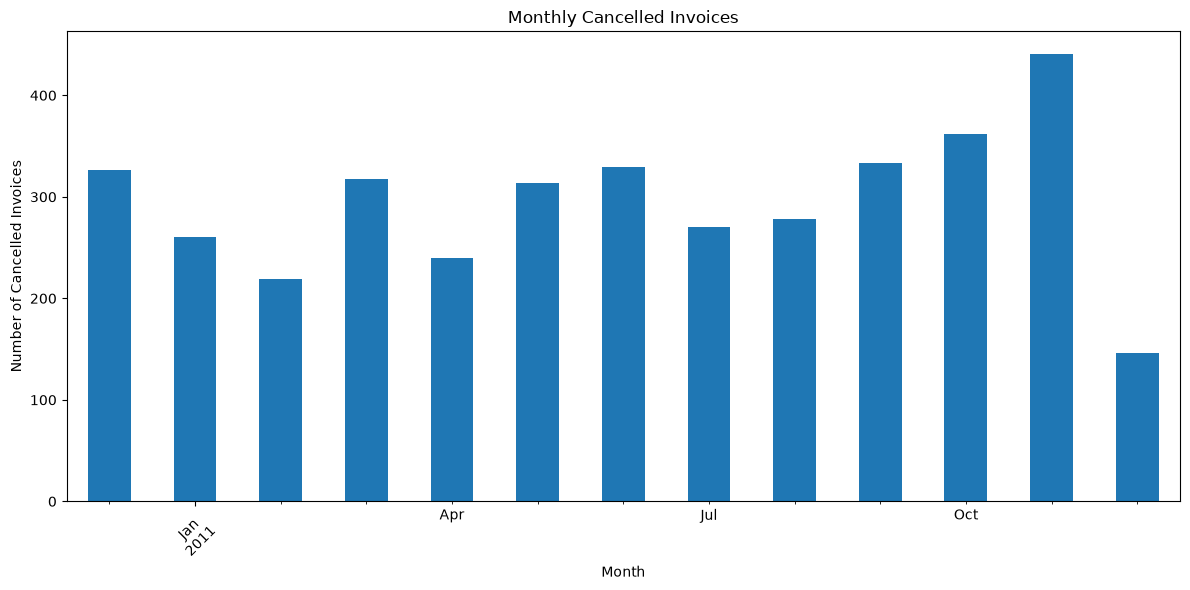

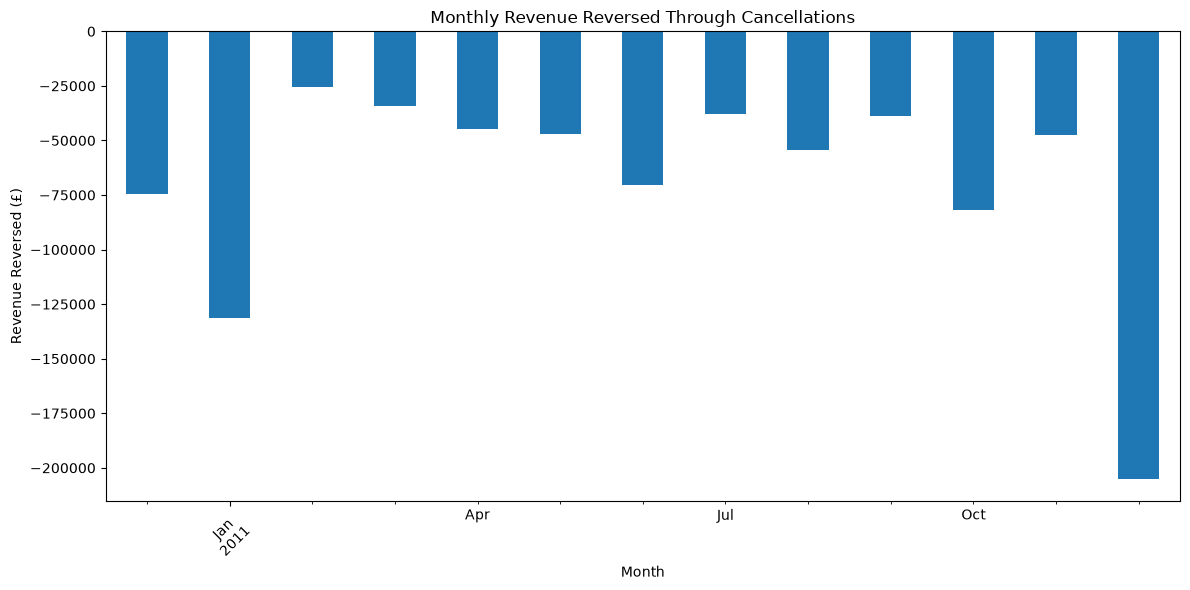

In [149]:
# Visualise monthly cancelled invoices

plt.figure(figsize=(12, 6))

monthly_cancellations["Cancelled_Invoices"].plot(kind="bar")

plt.title("Monthly Cancelled Invoices")
plt.xlabel("Month")
plt.ylabel("Number of Cancelled Invoices")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


# Visualise monthly revenue reversed through cancellations

plt.figure(figsize=(12, 6))

monthly_cancellations["Revenue_Reversed"].plot(kind="bar")

plt.title("Monthly Revenue Reversed Through Cancellations")
plt.xlabel("Month")
plt.ylabel("Revenue Reversed (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### Monthly Cancellation Visualisation — Key Findings

- November 2011 recorded the highest number of cancelled invoices,
  with 441 unique invoices.
- December 2011 recorded the highest revenue reversal,
  approximately £205,089.27.
- January 2011 also had a relatively high revenue reversal
  of approximately £131,363.05.
- Cancellation frequency and financial impact did not follow
  the same pattern.
- One unusually large cancellation, C581484, contributed
  approximately 82.1% of December's revenue reversal.

**Business Insight:**

A higher number of cancelled invoices does not necessarily
translate into a higher financial impact. The value of individual
cancelled transactions also matters. December's unusually high
revenue reversal was heavily influenced by one large transaction.

December 2011 is incomplete because the dataset ends on December 9,
so its figures should be interpreted separately.

In [150]:
# Find the largest cancelled invoices in December 2011

december_cancellations = cancellations[
    cancellations["YearMonth"] == "2011-12"
]

december_invoice_revenue = (
    december_cancellations.groupby("InvoiceNo")["Revenue"]
    .sum()
    .sort_values()
)

december_invoice_revenue.head(10)

InvoiceNo
C581484   -168469.60
C580605    -17836.46
C580604    -11586.50
C580726     -1100.44
C580971      -664.86
C580954      -436.20
C580968      -381.95
C581228      -336.00
C581229      -269.96
C580702      -238.00
Name: Revenue, dtype: float64

### December 2011 — High-Value Cancellation Investigation

- December recorded the highest monthly revenue reversal,
  at £205,089.27.
- Invoice C581484 alone contributed £168,469.60,
  approximately 82.1% of December's total reversal.
- The unusually high monthly figure is therefore heavily
  influenced by a single cancelled invoice.

**Business Insight:**

December's high cancellation value is primarily driven by
one exceptionally large cancellation. Monthly cancellation
totals should therefore be interpreted alongside individual
invoice values to avoid misleading conclusions.

In [151]:
# Inspect the largest December cancellation

largest_cancellation = cancellations[
    cancellations["InvoiceNo"] == "C581484"
]

largest_cancellation[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "Revenue"]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue
535161,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,-168469.6


### Investigation of Invoice C581484

- Invoice C581484 contains a cancellation of 80,995 units
  of PAPER CRAFT, LITTLE BIRDIE.
- The unit price was £2.08.
- The total revenue reversal was £168,469.60.
- This single invoice accounts for approximately 82.1% of
  December 2011's total cancellation revenue.

**Business Insight:**

A single high-volume product cancellation had a substantial
impact on the retailer's monthly revenue reversal. This
demonstrates why invoice-level investigation is important
when analysing unusual financial patterns.

In [152]:
# Search for the original transaction of this product

original_transaction = df[
    (df["StockCode"].astype(str) == "23843") &
    (df["Quantity"] > 0)
]

original_transaction[
    ["InvoiceNo", "StockCode", "Description",
     "Quantity", "UnitPrice", "Revenue", "InvoiceDate"]
].sort_values("InvoiceDate")

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue,InvoiceDate
535160,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.6,2011-12-09 09:15:00


### Original Sale and Cancellation Matching

An investigation of invoice C581484 revealed a matching
positive transaction:

- Original invoice: 535160
- Cancellation invoice: C581484
- Product: PAPER CRAFT, LITTLE BIRDIE
- Original quantity: 80,995 units
- Cancelled quantity: -80,995 units
- Unit price: £2.08
- Original revenue: £168,469.60
- Cancellation revenue: -£168,469.60

The positive and negative transactions have matching quantities
and unit prices, resulting in a combined revenue impact of £0.

**Business Insight:**

The unusually high December cancellation value was primarily
caused by the reversal of a single high-value transaction.
Matching positive and negative records helps explain unusual
revenue movements and prevents misleading sales conclusions.

In [153]:
# Separate positive and negative quantity transactions

positive_transactions = df[df["Quantity"] > 0].copy()
negative_transactions = df[df["Quantity"] < 0].copy()

# Convert negative quantities to positive values for comparison
negative_transactions["Quantity"] = (
    negative_transactions["Quantity"].abs()
)

print("Positive transaction records:", len(positive_transactions))
print("Negative transaction records:", len(negative_transactions))

Positive transaction records: 526054
Negative transaction records: 10587


In [154]:
# Find potential matches between positive and negative transactions

positive_keys = positive_transactions[
    ["StockCode", "Quantity", "UnitPrice"]
].drop_duplicates()

negative_keys = negative_transactions[
    ["StockCode", "Quantity", "UnitPrice"]
].drop_duplicates()

matching_keys = positive_keys.merge(
    negative_keys,
    on=["StockCode", "Quantity", "UnitPrice"],
    how="inner"
)

print("Unique positive transaction combinations:", len(positive_keys))
print("Unique negative transaction combinations:", len(negative_keys))
print("Matching product-quantity-price combinations:", len(matching_keys))

Unique positive transaction combinations: 65621
Unique negative transaction combinations: 6928
Matching product-quantity-price combinations: 4134


In [155]:
# Retrieve positive records with matching negative combinations

matched_positive = positive_transactions.merge(
    matching_keys,
    on=["StockCode", "Quantity", "UnitPrice"],
    how="inner"
)

# Retrieve negative records with matching positive combinations

matched_negative = negative_transactions.merge(
    matching_keys,
    on=["StockCode", "Quantity", "UnitPrice"],
    how="inner"
)

print("Positive records with matching combinations:", len(matched_positive))
print("Negative records with matching combinations:", len(matched_negative))

Positive records with matching combinations: 163261
Negative records with matching combinations: 7499


In [156]:
# Check whether a matching positive transaction occurred
# before each negative transaction

positive_dates = positive_transactions[
    ["StockCode", "Quantity", "UnitPrice", "InvoiceDate"]
].rename(columns={
    "InvoiceDate": "Positive_Date"
})

negative_dates = negative_transactions[
    ["InvoiceNo", "StockCode", "Quantity", "UnitPrice", "InvoiceDate"]
].rename(columns={
    "InvoiceDate": "Negative_Date"
})

date_matches = negative_dates.merge(
    positive_dates,
    on=["StockCode", "Quantity", "UnitPrice"],
    how="inner"
)

date_matches["Positive_Before_Negative"] = (
    date_matches["Positive_Date"] < date_matches["Negative_Date"]
)

print(
    "Negative records with at least one earlier matching positive record:",
    date_matches.groupby(
        ["InvoiceNo", "StockCode", "Quantity", "UnitPrice"]
    )["Positive_Before_Negative"].any().sum()
)

Negative records with at least one earlier matching positive record: 7067


### Positive and Negative Transaction Matching

- 4,134 unique product-quantity-price combinations appeared in both
  positive and negative transaction records.
- 7,499 negative transaction rows had a matching combination somewhere
  among positive transactions.
- The date-based comparison identified 7,067 negative
  invoice-product-quantity-price combinations with at least one earlier
  positive combination.
- These figures describe matching patterns in the dataset; they do not
  establish a link to the exact original sale.

**Business Insight:**

A substantial number of negative transactions have an earlier positive
transaction with the same product, quantity, and unit price. This is
consistent with possible reversals, but matching these fields alone
cannot prove that a particular sale was returned or cancelled.


In [157]:
# Identify negative transaction combinations
# without an earlier positive match

earlier_match_keys = (
    date_matches[
        date_matches["Positive_Before_Negative"]
    ][["InvoiceNo", "StockCode", "Quantity", "UnitPrice"]]
    .drop_duplicates()
)

unmatched_negative = negative_dates.merge(
    earlier_match_keys,
    on=["InvoiceNo", "StockCode", "Quantity", "UnitPrice"],
    how="left",
    indicator=True
)

unmatched_negative = unmatched_negative[
    unmatched_negative["_merge"] == "left_only"
]

print("Negative records without an earlier matching combination:",
      len(unmatched_negative))

Negative records without an earlier matching combination: 3520


In [158]:
# Retrieve details of unmatched negative transactions

unmatched_details = negative_transactions.merge(
    unmatched_negative[
        ["InvoiceNo", "StockCode", "Quantity", "UnitPrice"]
    ].drop_duplicates(),
    on=["InvoiceNo", "StockCode", "Quantity", "UnitPrice"],
    how="inner"
)

print("Invoice number types:")
print(
    unmatched_details["InvoiceNo"]
    .astype(str)
    .str.startswith("C")
    .value_counts()
)

print("\nMissing descriptions:")
print(unmatched_details["Description"].isna().sum())

print("\nUnit price summary:")
print(unmatched_details["UnitPrice"].describe())

print("\nMost common descriptions:")
print(unmatched_details["Description"].value_counts().head(10))

Invoice number types:
InvoiceNo
True     2202
False    1318
Name: count, dtype: int64

Missing descriptions:
848

Unit price summary:
count     3520.000000
mean       109.411469
std       1052.734380
min          0.000000
25%          0.000000
50%          1.060000
75%          4.150000
max      38970.000000
Name: UnitPrice, dtype: float64

Most common descriptions:
Description
Manual                      194
check                       120
POSTAGE                      89
Discount                     77
REGENCY CAKESTAND 3 TIER     70
SAMPLES                      60
damages                      45
damaged                      42
?                            41
AMAZON FEE                   30
Name: count, dtype: int64


In [159]:
# Investigate the highest-priced unmatched negative records

high_price_records = (
    unmatched_details
    .sort_values("UnitPrice", ascending=False)
    .head(10)
)

high_price_records[
    [
        "InvoiceNo",
        "StockCode",
        "Description",
        "Quantity",
        "UnitPrice",
        "Revenue",
        "InvoiceDate"
    ]
]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,Revenue,InvoiceDate
1868,C556445,M,Manual,1,38970.00,-38970.00,2011-06-10 15:31:00
3462,C580605,AMAZONFEE,AMAZON FEE,1,17836.46,-17836.46,2011-12-05 11:36:00
398,C540117,AMAZONFEE,AMAZON FEE,1,16888.02,-16888.02,2011-01-05 09:55:00
399,C540118,AMAZONFEE,AMAZON FEE,1,16453.71,-16453.71,2011-01-05 09:57:00
160,C537630,AMAZONFEE,AMAZON FEE,1,13541.33,-13541.33,2010-12-07 15:04:00
161,C537644,AMAZONFEE,AMAZON FEE,1,13474.79,-13474.79,2010-12-07 15:34:00
3461,C580604,AMAZONFEE,AMAZON FEE,1,11586.50,-11586.50,2011-12-05 11:35:00
3189,C574902,AMAZONFEE,AMAZON FEE,1,8286.22,-8286.22,2011-11-07 15:21:00
1549,C551685,POST,POSTAGE,1,8142.75,-8142.75,2011-05-03 12:51:00
2585,C566899,AMAZONFEE,AMAZON FEE,1,7427.97,-7427.97,2011-09-15 13:53:00


In [160]:
# Analyse Amazon fee records among unmatched negative transactions

amazon_fee_records = unmatched_details[
    unmatched_details["StockCode"].astype(str) == "AMAZONFEE"
]

print("Total Amazon fee records:", len(amazon_fee_records))

print(
    "Unique Amazon fee invoices:",
    amazon_fee_records["InvoiceNo"].nunique()
)

print(
    "Total Amazon fee revenue:",
    round(amazon_fee_records["Revenue"].sum(), 2)
)

print("\nAmazon fee price statistics:")
print(amazon_fee_records["UnitPrice"].describe())

Total Amazon fee records: 30
Unique Amazon fee invoices: 30
Total Amazon fee revenue: -221520.5

Amazon fee price statistics:
count       30.000000
mean      7384.016667
std       4258.334667
min          1.000000
25%       5323.890000
50%       5909.875000
75%       7322.685000
max      17836.460000
Name: UnitPrice, dtype: float64


In [161]:
# Analyse Manual records among unmatched negative transactions

manual_records = unmatched_details[
    unmatched_details["StockCode"].astype(str) == "M"
]

print("Total Manual records:", len(manual_records))

print(
    "Unique Manual invoices:",
    manual_records["InvoiceNo"].nunique()
)

print(
    "Total Manual revenue:",
    round(manual_records["Revenue"].sum(), 2)
)

print("\nManual price statistics:")
print(manual_records["UnitPrice"].describe())

print("\nManual record details:")
print(
    manual_records[
        ["InvoiceNo", "Description", "Quantity",
         "UnitPrice", "Revenue", "InvoiceDate"]
    ].sort_values("UnitPrice", ascending=False).head(10)
)

Total Manual records: 194
Unique Manual invoices: 181
Total Manual revenue: -128606.77

Manual price statistics:
count      194.000000
mean       630.004175
std       2898.787574
min          0.030000
25%          5.512500
50%        122.790000
75%        442.752500
max      38970.000000
Name: UnitPrice, dtype: float64

Manual record details:
     InvoiceNo Description  Quantity  UnitPrice   Revenue         InvoiceDate
1868   C556445      Manual         1   38970.00 -38970.00 2011-06-10 15:31:00
1553   C551699      Manual         1    6930.00  -6930.00 2011-05-03 14:12:00
2110   C560372      Manual         1    4287.63  -4287.63 2011-07-18 12:26:00
3079   C573079      Manual         2    4161.06  -8322.12 2011-10-27 14:15:00
2984   C571750      Manual         1    3949.32  -3949.32 2011-10-19 11:16:00
2323   C562647      Manual         1    3155.95  -3155.95 2011-08-08 12:56:00
2142   C560647      Manual         1    3060.60  -3060.60 2011-07-20 11:31:00
2620   C567352      Manual     

In [162]:
# Analyse postage records among unmatched negative transactions

postage_records = unmatched_details[
    unmatched_details["StockCode"].astype(str) == "POST"
]

print("Total Postage records:", len(postage_records))

print(
    "Unique Postage invoices:",
    postage_records["InvoiceNo"].nunique()
)

print(
    "Total Postage revenue:",
    round(postage_records["Revenue"].sum(), 2)
)

print("\nPostage price statistics:")
print(postage_records["UnitPrice"].describe())

print("\nPostage record details:")
print(
    postage_records[
        ["InvoiceNo", "Description", "Quantity",
         "UnitPrice", "Revenue", "InvoiceDate"]
    ].sort_values("UnitPrice", ascending=False).head(10)
)

Total Postage records: 89
Unique Postage invoices: 87
Total Postage revenue: -10761.84

Postage price statistics:
count      89.000000
mean      120.155506
std       862.682288
min         1.720000
25%         4.410000
50%         8.650000
75%        29.280000
max      8142.750000
Name: UnitPrice, dtype: float64

Postage record details:
     InvoiceNo Description  Quantity  UnitPrice  Revenue         InvoiceDate
1549   C551685     POSTAGE         1    8142.75 -8142.75 2011-05-03 12:51:00
1933   C557638     POSTAGE         1     545.58  -545.58 2011-06-21 16:01:00
3162   C574344     POSTAGE         1     262.73  -262.73 2011-11-04 10:18:00
2485   C565229     POSTAGE         1     200.00  -200.00 2011-09-02 09:12:00
2443   C564905     POSTAGE         1      87.40   -87.40 2011-08-31 12:16:00
2724   C568410     POSTAGE         1      80.00   -80.00 2011-09-27 10:42:00
2444   C564905     POSTAGE         1      79.68   -79.68 2011-08-31 12:16:00
1711   C554010     POSTAGE         1      75.

In [163]:
# Analyse Discount records among unmatched negative transactions

discount_records = unmatched_details[
    unmatched_details["Description"].astype(str).str.upper() == "DISCOUNT"
]

print("Total Discount records:", len(discount_records))

print(
    "Unique Discount invoices:",
    discount_records["InvoiceNo"].nunique()
)

print(
    "Total Discount revenue:",
    round(discount_records["Revenue"].sum(), 2)
)

print("\nDiscount price statistics:")
print(discount_records["UnitPrice"].describe())

print("\nDiscount record details:")
print(
    discount_records[
        ["InvoiceNo", "StockCode", "Description", "Quantity",
         "UnitPrice", "Revenue", "InvoiceDate"]
    ].sort_values("UnitPrice").head(10)
)

Total Discount records: 77
Unique Discount invoices: 65
Total Discount revenue: -5696.22

Discount price statistics:
count      77.000000
mean       72.484545
std       219.271071
min         0.010000
25%        13.880000
50%        22.970000
75%        57.600000
max      1867.860000
Name: UnitPrice, dtype: float64

Discount record details:
     InvoiceNo StockCode Description  Quantity  UnitPrice  Revenue  \
932    C545478         D    Discount       720       0.01    -7.20   
1610   C552569         D    Discount       240       0.03    -7.20   
1699   C553841         D    Discount        48       0.20    -9.60   
1879   C556796         D    Discount        96       0.70   -67.20   
1611   C552650         D    Discount        18       1.45   -26.10   
305    C538897         D    Discount         1       5.76    -5.76   
3249   C576244         D    Discount         1       6.00    -6.00   
2371   C563592         D    Discount         1       9.60    -9.60   
1659   C553482         D   

In [164]:
# Analyse unmatched negative transactions with missing descriptions

missing_description_records = unmatched_details[
    unmatched_details["Description"].isna()
]

print(
    "Records with missing descriptions:",
    len(missing_description_records)
)

print(
    "Unique invoices:",
    missing_description_records["InvoiceNo"].nunique()
)

print(
    "Total negative revenue:",
    round(missing_description_records["Revenue"].sum(), 2)
)

print("\nStockCode distribution:")
print(
    missing_description_records["StockCode"]
    .value_counts()
    .head(15)
)

print("\nUnitPrice statistics:")
print(missing_description_records["UnitPrice"].describe())

Records with missing descriptions: 848
Unique invoices: 848
Total negative revenue: 0.0

StockCode distribution:
StockCode
21161     3
22162     3
22034     3
20966     3
20892     3
84631     3
22114     3
85017A    3
22028     2
85067     2
21414     2
85126     2
21692     2
21172     2
84534B    2
Name: count, dtype: int64

UnitPrice statistics:
count    848.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: UnitPrice, dtype: float64


In [165]:
# Summarise the categories investigated so far

category_summary = pd.DataFrame({
    "Category": [
        "Amazon Fees",
        "Manual Adjustments",
        "Postage",
        "Discounts",
        "Missing Descriptions"
    ],
    "Records": [
        len(amazon_fee_records),
        len(manual_records),
        len(postage_records),
        len(discount_records),
        len(missing_description_records)
    ],
    "Revenue": [
        amazon_fee_records["Revenue"].sum(),
        manual_records["Revenue"].sum(),
        postage_records["Revenue"].sum(),
        discount_records["Revenue"].sum(),
        missing_description_records["Revenue"].sum()
    ]
})

category_summary["Revenue"] = category_summary["Revenue"].round(2)

print(category_summary)
print("\nCombined revenue impact:")
print(round(category_summary["Revenue"].sum(), 2))

               Category  Records    Revenue
0           Amazon Fees       30 -221520.50
1    Manual Adjustments      194 -128606.77
2               Postage       89  -10761.84
3             Discounts       77   -5696.22
4  Missing Descriptions      848       0.00

Combined revenue impact:
-366585.33


In [166]:
# Identify unmatched negative records outside the investigated categories

investigated_indices = (
    amazon_fee_records.index
    .union(manual_records.index)
    .union(postage_records.index)
    .union(discount_records.index)
    .union(missing_description_records.index)
)

remaining_unmatched = unmatched_details.loc[
    ~unmatched_details.index.isin(investigated_indices)
].copy()

print("Remaining unmatched records:", len(remaining_unmatched))

print(
    "Unique invoices:",
    remaining_unmatched["InvoiceNo"].nunique()
)

print(
    "Remaining negative revenue:",
    round(remaining_unmatched["Revenue"].sum(), 2)
)

print("\nMost common descriptions:")
print(remaining_unmatched["Description"].value_counts().head(15))

Remaining unmatched records: 2282
Unique invoices: 1506
Remaining negative revenue: -70671.81

Most common descriptions:
Description
check                            120
REGENCY CAKESTAND 3 TIER          70
SAMPLES                           60
damages                           45
damaged                           42
?                                 41
Bank Charges                      25
SILVER HANGING T-LIGHT HOLDER     21
sold as set on dotcom             20
LARGE CIRCULAR MIRROR MOBILE      19
CRUK Commission                   16
SMALL GLASS HEART TRINKET POT     15
JAM MAKING SET WITH JARS          15
Damaged                           14
POPCORN HOLDER                    14
Name: count, dtype: int64


In [167]:
# Investigate records described as "check"

check_records = remaining_unmatched[
    remaining_unmatched["Description"].astype(str).str.strip().str.lower() == "check"
].copy()

print("Total check records:", len(check_records))

print(
    "Unique check invoices:",
    check_records["InvoiceNo"].nunique()
)

print(
    "Total check revenue:",
    round(check_records["Revenue"].sum(), 2)
)

print("\nStockCode distribution:")
print(check_records["StockCode"].value_counts().head(15))

print("\nCheck record details:")
print(
    check_records[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue", "InvoiceDate"]
    ].head(15)
)

Total check records: 123
Unique check invoices: 123
Total check revenue: 0.0

StockCode distribution:
StockCode
72802C    3
72802B    3
22943     2
35648     2
84968F    1
84968E    1
84249A    1
84598     1
90195A    1
90210D    1
90012B    1
90014A    1
47574A    1
21823     1
21803     1
Name: count, dtype: int64

Check record details:
     InvoiceNo StockCode Description  Quantity  UnitPrice  Revenue  \
125     537425    84968F       check        20        0.0     -0.0   
126     537426    84968E       check        35        0.0     -0.0   
937     545546    84249A       check       150        0.0     -0.0   
986     545990     84598       check      3000        0.0     -0.0   
2806    569875    90195A       check        45        0.0     -0.0   
2807    569876    90210D       check        28        0.0     -0.0   
2810    569879    90012B       check         5        0.0     -0.0   
2814    569883    90014A       check        12        0.0     -0.0   
2905    570403    47574A     

In [168]:
# Investigate SAMPLES records

sample_records = remaining_unmatched[
    remaining_unmatched["Description"].astype(str).str.strip().str.upper() == "SAMPLES"
].copy()

print("Total sample records:", len(sample_records))

print(
    "Unique sample invoices:",
    sample_records["InvoiceNo"].nunique()
)

print(
    "Total sample revenue:",
    round(sample_records["Revenue"].sum(), 2)
)

print("\nUnit price statistics:")
print(sample_records["UnitPrice"].describe())

print("\nSample record details:")
print(
    sample_records[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue", "InvoiceDate"]
    ].head(15)
)

Total sample records: 61
Unique sample invoices: 18
Total sample revenue: -3102.7

Unit price statistics:
count     61.000000
mean      50.863934
std       87.089952
min        0.000000
25%        7.000000
50%       16.500000
75%       65.850000
max      570.000000
Name: UnitPrice, dtype: float64

Sample record details:
    InvoiceNo StockCode Description  Quantity  UnitPrice  Revenue  \
142   C537581         S     SAMPLES         1      12.95   -12.95   
143   C537581         S     SAMPLES         1      52.00   -52.00   
858   C544580         S     SAMPLES         1       5.74    -5.74   
859   C544580         S     SAMPLES         1      11.08   -11.08   
860   C544580         S     SAMPLES         1       5.79    -5.79   
861   C544580         S     SAMPLES         1       6.70    -6.70   
862   C544580         S     SAMPLES         1       8.74    -8.74   
863   C544580         S     SAMPLES         1       9.74    -9.74   
864   C544580         S     SAMPLES         1       9.99 

In [169]:
# Investigate damage-related records

damage_records = remaining_unmatched[
    remaining_unmatched["Description"]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["damaged", "damages"])
].copy()

print("Total damage-related records:", len(damage_records))

print(
    "Unique invoices:",
    damage_records["InvoiceNo"].nunique()
)

print(
    "Total negative revenue:",
    round(damage_records["Revenue"].sum(), 2)
)

print("\nDescription distribution:")
print(damage_records["Description"].value_counts())

print("\nUnit price statistics:")
print(damage_records["UnitPrice"].describe())

print("\nDamage-related record details:")
print(
    damage_records[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue", "InvoiceDate"]
    ].head(20)
)

Total damage-related records: 103
Unique invoices: 103
Total negative revenue: 0.0

Description distribution:
Description
damages    45
damaged    42
Damaged    14
DAMAGED     1
Damages     1
Name: count, dtype: int64

Unit price statistics:
count    103.0
mean       0.0
std        0.0
min        0.0
25%        0.0
50%        0.0
75%        0.0
max        0.0
Name: UnitPrice, dtype: float64

Damage-related record details:
     InvoiceNo StockCode Description  Quantity  UnitPrice  Revenue  \
128     537432    35833G     damages        43        0.0     -0.0   
471     540638    72038P     damages       990        0.0     -0.0   
914     545236     22797     damages        15        0.0     -0.0   
987     546010     22423     damages        19        0.0     -0.0   
1002    546140     21527     damages        30        0.0     -0.0   
1030    546409     21833     damages       110        0.0     -0.0   
1198    548620    84313B     Damaged        32        0.0     -0.0   
1234    548999

In [170]:
# Investigate Bank Charges records

bank_charge_records = remaining_unmatched[
    remaining_unmatched["Description"]
    .astype(str)
    .str.strip()
    .str.lower() == "bank charges"
].copy()

print("Total Bank Charges records:", len(bank_charge_records))

print(
    "Unique invoices:",
    bank_charge_records["InvoiceNo"].nunique()
)

print(
    "Total Bank Charges revenue:",
    round(bank_charge_records["Revenue"].sum(), 2)
)

print("\nUnit price statistics:")
print(bank_charge_records["UnitPrice"].describe())

print("\nBank Charges record details:")
print(
    bank_charge_records[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue", "InvoiceDate"]
    ].head(20)
)

Total Bank Charges records: 25
Unique invoices: 25
Total Bank Charges revenue: -7340.64

Unit price statistics:
count      25.00000
mean      293.62560
std       290.40012
min        21.90000
25%        82.73000
50%       134.76000
75%       472.77000
max      1050.15000
Name: UnitPrice, dtype: float64

Bank Charges record details:
     InvoiceNo     StockCode   Description  Quantity  UnitPrice  Revenue  \
141    C537572  BANK CHARGES  Bank Charges         1      95.38   -95.38   
276    C538680  BANK CHARGES  Bank Charges         1     966.92  -966.92   
533    C541653  BANK CHARGES  Bank Charges         1    1050.15 -1050.15   
825    C544049  BANK CHARGES  Bank Charges         1     566.37  -566.37   
854    C544575  BANK CHARGES  Bank Charges         1     134.76  -134.76   
855    C544576  BANK CHARGES  Bank Charges         1     149.16  -149.16   
884    C544584  BANK CHARGES  Bank Charges         1     109.84  -109.84   
983    C545887  BANK CHARGES  Bank Charges         1     3

In [171]:
# Investigate CRUK Commission records

cruk_records = remaining_unmatched[
    remaining_unmatched["Description"]
    .astype(str)
    .str.strip()
    .str.lower() == "cruk commission"
].copy()

print("Total CRUK Commission records:", len(cruk_records))

print(
    "Unique invoices:",
    cruk_records["InvoiceNo"].nunique()
)

print(
    "Total CRUK Commission revenue:",
    round(cruk_records["Revenue"].sum(), 2)
)

print("\nUnit price statistics:")
print(cruk_records["UnitPrice"].describe())

print("\nCRUK Commission record details:")
print(
    cruk_records[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue", "InvoiceDate"]
    ]
)

Total CRUK Commission records: 16
Unique invoices: 16
Total CRUK Commission revenue: -7933.43

Unit price statistics:
count      16.000000
mean      495.839375
std       364.164786
min         1.600000
25%       284.252500
50%       471.770000
75%       668.977500
max      1100.440000
Name: UnitPrice, dtype: float64

CRUK Commission record details:
     InvoiceNo StockCode      Description  Quantity  UnitPrice  Revenue  \
2435   C564763      CRUK  CRUK Commission         1       1.60    -1.60   
2503   C565382      CRUK  CRUK Commission         1      13.01   -13.01   
2548   C566216      CRUK  CRUK Commission         1      15.96   -15.96   
2565   C566565      CRUK  CRUK Commission         1      52.24   -52.24   
2640   C567655      CRUK  CRUK Commission         1     608.66  -608.66   
2713   C568345      CRUK  CRUK Commission         1     447.56  -447.56   
2776   C569245      CRUK  CRUK Commission         1     361.59  -361.59   
2917   C570487      CRUK  CRUK Commission        

In [172]:
# Investigate records with an unknown description

unknown_records = remaining_unmatched[
    remaining_unmatched["Description"]
    .astype(str)
    .str.strip()
    == "?"
].copy()

print("Total unknown-description records:", len(unknown_records))

print(
    "Unique invoices:",
    unknown_records["InvoiceNo"].nunique()
)

print(
    "Total revenue impact:",
    round(unknown_records["Revenue"].sum(), 2)
)

print("\nUnit price statistics:")
print(unknown_records["UnitPrice"].describe())

print("\nRecord details:")
print(
    unknown_records[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue", "InvoiceDate"]
    ]
)

Total unknown-description records: 41
Unique invoices: 41
Total revenue impact: 0.0

Unit price statistics:
count    41.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: UnitPrice, dtype: float64

Record details:
     InvoiceNo StockCode Description  Quantity  UnitPrice  Revenue  \
90      537032     21275           ?        30        0.0     -0.0   
218     538090     20956           ?       723        0.0     -0.0   
396     540100     22837           ?       106        0.0     -0.0   
465     540558     21258           ?        29        0.0     -0.0   
474     540651     82599           ?       290        0.0     -0.0   
570     541882     48185           ?        57        0.0     -0.0   
709     542861    47591B           ?       207        0.0     -0.0   
838     544410    84997C           ?       741        0.0     -0.0   
888     544649     21621           ?       400        0.0     -0.0   
1001    546138     21815       

In [173]:
# Investigate "sold as set on dotcom" records

dotcom_set_records = remaining_unmatched[
    remaining_unmatched["Description"]
    .astype(str)
    .str.strip()
    .str.lower() == "sold as set on dotcom"
].copy()

print("Total records:", len(dotcom_set_records))

print(
    "Unique invoices:",
    dotcom_set_records["InvoiceNo"].nunique()
)

print(
    "Total revenue impact:",
    round(dotcom_set_records["Revenue"].sum(), 2)
)

print("\nUnit price statistics:")
print(dotcom_set_records["UnitPrice"].describe())

print("\nRecord details:")
print(
    dotcom_set_records[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue", "InvoiceDate"]
    ]
)

Total records: 20
Unique invoices: 20
Total revenue impact: 0.0

Unit price statistics:
count    20.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0
Name: UnitPrice, dtype: float64

Record details:
     InvoiceNo StockCode            Description  Quantity  UnitPrice  Revenue  \
1832    556232     21135  sold as set on dotcom       304        0.0     -0.0   
1833    556233     21136  sold as set on dotcom       272        0.0     -0.0   
1835    556260     37340  sold as set on dotcom        18        0.0     -0.0   
1836    556261    79051A  sold as set on dotcom         6        0.0     -0.0   
1837    556262     37327  sold as set on dotcom        95        0.0     -0.0   
1852    556307    37479P  sold as set on dotcom        30        0.0     -0.0   
1853    556308     22130  sold as set on dotcom       390        0.0     -0.0   
1854    556309     22856  sold as set on dotcom        30        0.0     -0.0   
1855    556310     229

In [174]:
# Investigate check records

print("Total check records:", len(check_records))

print("\nUnique StockCodes:")
print(check_records["StockCode"].value_counts().head(15))

print("\nQuantity statistics:")
print(check_records["Quantity"].describe())

print("\nMonthly distribution:")
print(
    check_records.groupby(
        check_records["InvoiceDate"].dt.to_period("M")
    ).size()
)

print("\nSample records:")
print(
    check_records[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue", "InvoiceDate"]
    ].head(15)
)

Total check records: 123

Unique StockCodes:
StockCode
72802C    3
72802B    3
22943     2
35648     2
84968F    1
84968E    1
84249A    1
84598     1
90195A    1
90210D    1
90012B    1
90014A    1
47574A    1
21823     1
21803     1
Name: count, dtype: int64

Quantity statistics:
count     123.000000
mean      108.788618
std       310.033691
min         3.000000
25%        22.500000
50%        41.000000
75%        91.000000
max      3000.000000
Name: Quantity, dtype: float64

Monthly distribution:
InvoiceDate
2010-12     2
2011-03     2
2011-10    35
2011-11    73
2011-12    11
Freq: M, dtype: int64

Sample records:
     InvoiceNo StockCode Description  Quantity  UnitPrice  Revenue  \
125     537425    84968F       check        20        0.0     -0.0   
126     537426    84968E       check        35        0.0     -0.0   
937     545546    84249A       check       150        0.0     -0.0   
986     545990     84598       check      3000        0.0     -0.0   
2806    569875    90195A

In [175]:
# Investigate damaged-product records

print("Total damaged records:", len(damage_records))

print("\nUnique invoices:", damage_records["InvoiceNo"].nunique())

print("\nTotal quantity:")
print(damage_records["Quantity"].sum())

print("\nStockCode distribution:")
print(damage_records["StockCode"].value_counts().head(15))

print("\nMonthly distribution:")
print(
    damage_records.groupby(
        damage_records["InvoiceDate"].dt.to_period("M")
    ).size()
)

print("\nQuantity statistics:")
print(damage_records["Quantity"].describe())

print("\nSample records:")
print(
    damage_records[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue", "InvoiceDate"]
    ].head(15)
)

Total damaged records: 103

Unique invoices: 103

Total quantity:
13752

StockCode distribution:
StockCode
22797     2
22423     2
35833G    1
72038P    1
21527     1
21833     1
84313B    1
84743C    1
21100     1
35915C    1
37488A    1
37487B    1
37482P    1
85167B    1
20827     1
Name: count, dtype: int64

Monthly distribution:
InvoiceDate
2010-12     1
2011-01     1
2011-03     4
2011-04    14
2011-05     8
2011-06    13
2011-07     4
2011-08     2
2011-09    14
2011-10    24
2011-11    15
2011-12     3
Freq: M, dtype: int64

Quantity statistics:
count     103.000000
mean      133.514563
std       322.566937
min         1.000000
25%        10.000000
50%        36.000000
75%        75.500000
max      1440.000000
Name: Quantity, dtype: float64

Sample records:
     InvoiceNo StockCode Description  Quantity  UnitPrice  Revenue  \
128     537432    35833G     damages        43        0.0     -0.0   
471     540638    72038P     damages       990        0.0     -0.0   
914     545236

In [176]:
# Investigate bank charge records

print("Total bank charge records:", len(bank_charge_records))

print(
    "Unique invoices:",
    bank_charge_records["InvoiceNo"].nunique()
)

print(
    "Total revenue impact:",
    round(bank_charge_records["Revenue"].sum(), 2)
)

print("\nStockCodes:")
print(bank_charge_records["StockCode"].value_counts())

print("\nUnit price statistics:")
print(bank_charge_records["UnitPrice"].describe())

print("\nRecord details:")
print(
    bank_charge_records[
        ["InvoiceNo", "StockCode", "Description",
         "Quantity", "UnitPrice", "Revenue", "InvoiceDate"]
    ]
)

Total bank charge records: 25
Unique invoices: 25
Total revenue impact: -7340.64

StockCodes:
StockCode
BANK CHARGES    25
Name: count, dtype: int64

Unit price statistics:
count      25.00000
mean      293.62560
std       290.40012
min        21.90000
25%        82.73000
50%       134.76000
75%       472.77000
max      1050.15000
Name: UnitPrice, dtype: float64

Record details:
     InvoiceNo     StockCode   Description  Quantity  UnitPrice  Revenue  \
141    C537572  BANK CHARGES  Bank Charges         1      95.38   -95.38   
276    C538680  BANK CHARGES  Bank Charges         1     966.92  -966.92   
533    C541653  BANK CHARGES  Bank Charges         1    1050.15 -1050.15   
825    C544049  BANK CHARGES  Bank Charges         1     566.37  -566.37   
854    C544575  BANK CHARGES  Bank Charges         1     134.76  -134.76   
855    C544576  BANK CHARGES  Bank Charges         1     149.16  -149.16   
884    C544584  BANK CHARGES  Bank Charges         1     109.84  -109.84   
983    C54

In [177]:
# Summarise the remaining unmatched records

print("Remaining records:", len(remaining_unmatched))

print(
    "Unique invoices:",
    remaining_unmatched["InvoiceNo"].nunique()
)

print(
    "Total revenue impact:",
    round(remaining_unmatched["Revenue"].sum(), 2)
)

print("\nMost common descriptions:")
print(
    remaining_unmatched["Description"]
    .value_counts(dropna=False)
    .head(20)
)

print("\nRevenue by description:")
print(
    remaining_unmatched.groupby(
        "Description", dropna=False
    )["Revenue"]
    .agg(["count", "sum"])
    .sort_values("sum")
    .head(20)
)

Remaining records: 2282
Unique invoices: 1506
Total revenue impact: -70671.81

Most common descriptions:
Description
check                                 120
REGENCY CAKESTAND 3 TIER               70
SAMPLES                                60
damages                                45
damaged                                42
?                                      41
Bank Charges                           25
SILVER HANGING T-LIGHT HOLDER          21
sold as set on dotcom                  20
LARGE CIRCULAR MIRROR MOBILE           19
CRUK Commission                        16
SMALL GLASS HEART TRINKET POT          15
JAM MAKING SET WITH JARS               15
Damaged                                14
POPCORN HOLDER                         14
COLOUR GLASS. STAR T-LIGHT HOLDER      13
JUMBO BAG RED RETROSPOT                13
VICTORIAN SEWING BOX LARGE             13
WHITE HANGING HEART T-LIGHT HOLDER     12
VICTORIAN GLASS HANGING T-LIGHT        11
Name: count, dtype: int64

Revenue by descr

In [178]:
# Investigate REGENCY CAKESTAND 3 TIER

regency_returns = remaining_unmatched[
    remaining_unmatched["Description"]
    .astype(str)
    .str.strip()
    .str.upper() == "REGENCY CAKESTAND 3 TIER"
].copy()

print("Negative transaction records:", len(regency_returns))

print("\nTotal quantity:")
print(regency_returns["Quantity"].sum())

print("\nTotal revenue impact:")
print(round(regency_returns["Revenue"].sum(), 2))

print("\nNegative transaction details:")
print(
    regency_returns[
        ["InvoiceNo", "StockCode", "Quantity",
         "UnitPrice", "Revenue", "CustomerID", "InvoiceDate"]
    ].sort_values("InvoiceDate")
)

Negative transaction records: 70

Total quantity:
350

Total revenue impact:
-3866.7

Negative transaction details:
     InvoiceNo StockCode  Quantity  UnitPrice  Revenue  CustomerID  \
155    C537602     22423         2      10.95   -21.90     17511.0   
171    C537797     22423         2      10.95   -21.90     13113.0   
183    C537812     22423        10      10.95  -109.50     14299.0   
279    C538690     22423        10      10.95  -109.50     13802.0   
329    C539253     22423        10      10.95  -109.50     17188.0   
...        ...       ...       ...        ...      ...         ...   
2916   C570478     22423         3      10.95   -32.85     14644.0   
3077   C573037     22423        11      10.95  -120.45     12471.0   
3134   C573756     22423         3      10.95   -32.85     17865.0   
3199   C575058     22423         1      10.95   -10.95     16013.0   
3425   C579758     22423         1      10.95   -10.95     14644.0   

             InvoiceDate  
155  2010-12-07 

### Standardising Unmatched Transaction Descriptions

Descriptions can differ because of capitalisation, leading or trailing spaces,
or missing values. The next cell standardises these labels for consistent
category counts. This changes only the analysis copy, not the cleaned source
dataset.


In [179]:
# Standardise descriptions in the remaining unmatched records

remaining_unmatched["Description_Normalized"] = (
    remaining_unmatched["Description"]
    .fillna("Missing Description")
    .astype(str)
    .str.strip()
    .str.lower()
)

# Summarise record counts, unique invoices, and revenue impact
description_summary = (
    remaining_unmatched
    .groupby("Description_Normalized")
    .agg(
        Record_Count=("InvoiceNo", "count"),
        Unique_Invoices=("InvoiceNo", "nunique"),
        Revenue_Impact=("Revenue", "sum")
    )
    .sort_values("Record_Count", ascending=False)
)

description_summary.head(20)


,Record_Count,Unique_Invoices,Revenue_Impact
Description_Normalized,,,
check,123,123,0.00
regency cakestand 3 tier,70,70,-3866.70
samples,61,18,-3102.70
damaged,57,57,0.00
damages,46,46,0.00
?,41,41,0.00
bank charges,25,25,-7340.64
silver hanging t-light holder,21,21,-282.00
sold as set on dotcom,20,20,0.00


### Unmatched Negative Transactions

Some negative transactions could not be matched to an earlier
positive transaction using the same StockCode, quantity and
UnitPrice.

These records require further investigation because they may
represent merchandise returns, financial adjustments, or
inventory-related activities.

The absence of an exact match does not necessarily mean that
the original sale never occurred.

In [180]:
# Match Regency Cakestand negative transactions
# with earlier positive transactions from the same customers

regency_positive = df[
    (df["StockCode"].astype(str) == "22423") &
    (df["Quantity"] > 0) &
    (df["CustomerID"].notna())
].copy()

regency_negative = regency_returns[
    regency_returns["CustomerID"].notna()
].copy()

regency_matches = regency_negative.merge(
    regency_positive[
        ["CustomerID", "StockCode", "Quantity",
         "UnitPrice", "InvoiceDate", "InvoiceNo"]
    ],
    on=["CustomerID", "StockCode"],
    suffixes=("_negative", "_positive")
)

regency_matches["Earlier_Purchase"] = (
    regency_matches["InvoiceDate_positive"] <
    regency_matches["InvoiceDate_negative"]
)

print(
    "Negative transactions with an earlier purchase "
    "by the same customer:",
    regency_matches.groupby("InvoiceNo_negative")[
        "Earlier_Purchase"
    ].any().sum()
)

print("\nTotal negative invoices:", regency_negative["InvoiceNo"].nunique())

Negative transactions with an earlier purchase by the same customer: 58

Total negative invoices: 70


In [181]:
# Check whether candidate earlier purchases also match
# the returned quantity and unit price

regency_matches["Quantity_Match"] = (
    regency_matches["Quantity_negative"].abs()
    == regency_matches["Quantity_positive"]
)

regency_matches["Price_Match"] = (
    regency_matches["UnitPrice_negative"]
    == regency_matches["UnitPrice_positive"]
)

regency_matches["Strong_Candidate"] = (
    regency_matches["Earlier_Purchase"]
    & regency_matches["Quantity_Match"]
    & regency_matches["Price_Match"]
)

strong_matches = regency_matches[
    regency_matches["Strong_Candidate"]
]

print(
    "Negative invoices with an earlier purchase "
    "matching quantity and price:",
    strong_matches["InvoiceNo_negative"].nunique()
)

Negative invoices with an earlier purchase matching quantity and price: 0


### Regency Cake Stand Return Investigation

- 70 negative transaction rows were identified for Regency Cake Stand.
- 58 had at least one earlier positive purchase of the same product
  by the same customer.
- None of the 58 candidate matches had an earlier purchase matching
  both the returned quantity and unit price exactly.

**Business Insight:**

The customer and product matches suggest a possible relationship
between earlier purchases and negative transactions. However, exact
purchase-level matching was not established. Differences in returned
quantities, pricing, or multiple purchases may explain the lack of
exact matches.

The investigation frame displays absolute quantities for comparison; the original dataset contains negative quantities for these rows.\n\nThese transactions are therefore treated as potential returns,
not confirmed returns.

## 8. Final Exploratory Data Analysis Summary

### Key Findings

**1. Monthly Revenue**
- November 2011 recorded the highest revenue among complete months,
  at approximately £1.46 million.
- Revenue increased considerably between September and November.
- December 2011 is incomplete because the dataset ends on December 9.

**2. Customer Purchasing Behaviour**
- Identifiable purchasing customers increased by approximately 31.4%
  between September and November.
- Orders per customer increased by approximately 15.2%.
- Average order value decreased by approximately 19.7%.
- Average units per order decreased by approximately 19.1%.
- Average revenue per unit remained relatively stable.
- These metrics describe monthly aggregates; they do not prove that
  the same individual customers increased their purchase frequency.

**3. Product Performance**
- PAPER CRAFT, LITTLE BIRDIE ranked first in total quantity sold.
- REGENCY CAKESTAND 3 TIER was among the highest-revenue merchandise
  products.
- WHITE HANGING HEART T-LIGHT HOLDER appeared in the highest number
  of unique orders among the products analysed.
- Product rankings varied depending on whether performance was
  measured by revenue, quantity, or order frequency.
- Postage and other non-merchandise descriptions should be separated
  from ordinary products when interpreting product rankings.

**4. Geographical Performance**
- The United Kingdom contributed approximately 92.6% of positive
  transaction revenue.
- The Netherlands generated the second-highest country revenue.
- Some international markets had high average order values despite
  relatively few orders.
- Large mean order quantities compared with medians suggest that a
  small number of large orders influence some country averages.

**5. Cancellations and Unusual Transactions**
- The dataset contained 9,251 records associated with C-prefixed
  cancellation invoices, representing 3,836 unique invoices.
- These records represented approximately £893,979.73 in negative
  revenue.
- November 2011 had the highest number of unique cancelled invoices
  (441).
- December 2011 had the largest revenue reversal (approximately
  £205,089.27), heavily influenced by one cancellation invoice.
- Negative transactions include possible merchandise returns,
  financial adjustments, postage, discounts, and operational records.
  They should not all be interpreted as customer returns.
- The Regency Cake Stand investigation found 58 of 70 negative
  invoices with an earlier purchase of the same product by the same
  customer, but none met the exact quantity-and-price matching rule.
  These are candidate relationships, not confirmed return links.

### Overall Business Conclusion

The retailer's revenue was heavily concentrated in the United Kingdom.
Revenue increased during September to November 2011, alongside growth
in identifiable purchasing customers and order frequency.

However, average order value and average units per order declined
during this period. Product performance also varied depending on
whether it was measured through revenue, quantity, or order frequency.

Cancellation analysis showed that frequency and financial impact are
different measures. A small number of high-value transactions can
materially affect monthly revenue reversals.

The analysis demonstrates the importance of examining customer
behaviour, product demand, geographical concentration, and transaction
quality together before drawing business conclusions.

### Data and Analysis Limitations

- CustomerID is missing for a substantial portion of transactions.
  Customer-level metrics therefore cover only identifiable customers.
- The dataset covers December 1, 2010 to December 9, 2011.
  December 2011 is incomplete and should not be compared directly
  with full months.
- Negative transactions cannot all be confirmed as customer returns.
- Matching product, quantity, price, customer, or date provides
  candidate evidence, not definitive transaction-level linkage.
- Some unusual transaction descriptions do not clearly explain
  the purpose of the transaction.
- Some international country averages are based on relatively few
  orders and may be influenced by unusually large transactions.
- Revenue is calculated as Quantity multiplied by UnitPrice and
  represents transaction-level revenue, not verified accounting
  revenue or cash received.
- Exact duplicate rows were removed during cleaning; other unusual
  and incomplete records were retained for investigation.
